# Clustering Analysis (K-Means)
**Dataset:** Iris flowers
**Goal:** Group similar flowers together using K-Means, choose the number of groups with the elbow method, and show the groups on scatter plots.
**Tools:** Python, scikit-learn, matplotlib, seaborn

## Load the data
I bring in the tools and load the iris file.

In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

os.makedirs("plot", exist_ok = True)
df = pd.read_csv("../datasets/1) Iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Look at the data
I check the size of the table and look for missing values.

In [11]:
print("Rows and columns are:", df.shape)
print("Missing values are:", df.isnull().sum())
df.describe().round(2)

Rows and columns are: (150, 5)
Missing values are: sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.05,3.76,1.20
std,0.83,0.43,1.76,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


## Choose the features
K-Means works with numbers, so I use the four measurement columns. I leave out the species column, because clustering should find groups on its own. I only use species at the end to check the result.

In [12]:
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X = df[features]
X.head()

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## Standardize the data
The columns have different sizes. Standardizing puts them all on the same scale (average 0, spread 1), so that no column counts more than the others just because its numbers are bigger.

In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pd.DataFrame(X_scaled, columns=features).describe().round(2)

,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,-0.00,-0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-1.87,-2.44,-1.57,-1.44
25%,-0.90,-0.59,-1.23,-1.18
50%,-0.05,-0.12,0.34,0.13
75%,0.67,0.57,0.76,0.79
max,2.49,3.11,1.79,1.71


## Find the best number of clusters (elbow method)
I run K-Means with 1 to 10 clusters and record the inertia each time. Inertia measures how far the points are from the centre of their group, so a smaller number means tighter groups. I look for the "elbow", the point where the line stops dropping quickly.

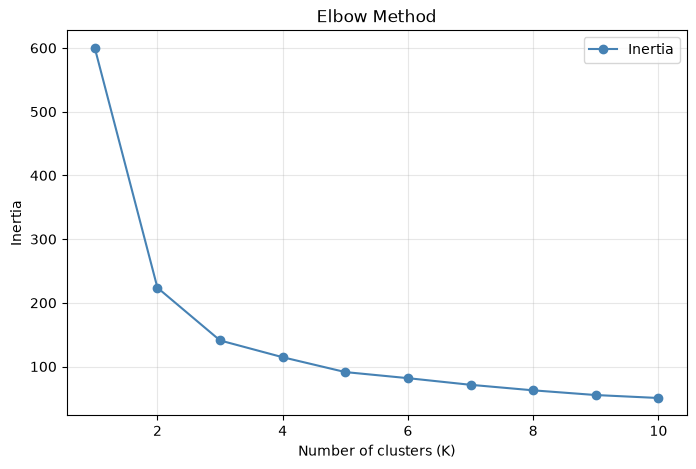

In [20]:
inertia = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker="o", color="steelblue", label="Inertia")
plt.title("Elbow Method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.legend()
plt.grid(alpha=0.3)

os.makedirs("plots", exist_ok=True)
plt.savefig("plots/elbow_method.png")
plt.show()

The inertia drops quickly up to K = 3 and then slows down, maintaining a gentle drop. This bend is the elbow, so I choose K = 3 clusters.

## Apply K-Means
I run K-Means with the number of clusters chosen from the elbow chart and add the cluster number to my table.

In [15]:
k = 3
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
df["cluster"] =kmeans.fit_predict(X_scaled)
df["cluster_name"] = "cluster" + df["cluster"].astype(str)
df["cluster"].value_counts().sort_index()


cluster
0    53
1    50
2    47
Name: count, dtype: int64

## What is each cluster like?
I find the average measurements of each cluster to understand how the groups differ.

In [16]:
df.groupby("cluster")[features].mean().round(2)

,sepal_length,sepal_width,petal_length,petal_width
cluster,,,,
0,5.80,2.67,4.37,1.41
1,5.01,3.42,1.46,0.24
2,6.78,3.10,5.51,1.97


Cluster 1 has the smallest petals  1.46cm long, cluster 2 has the largest petals 5.51 cm long, and cluster 0 is in between.

## Visualize the clusters
I draw each flower as a dot, coloured by its cluster. The black X marks show the centre of each cluster.

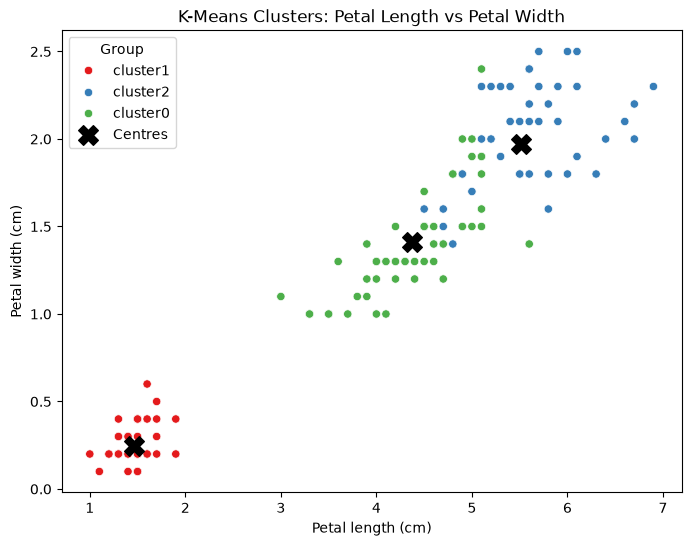

In [18]:


centers = scaler.inverse_transform(kmeans.cluster_centers_)
centers = pd.DataFrame(centers, columns=features)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x="petal_length",
    y="petal_width",
    hue="cluster_name",
    palette="Set1",
    data=df
)
plt.scatter(centers["petal_length"], centers["petal_width"],
            color="black", marker="X", s=200, label="Centres")
plt.title("K-Means Clusters: Petal Length vs Petal Width")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.legend(title="Group")
os.makedirs("plots", exist_ok=True)

plt.savefig("plots/clusters_petal.png")
plt.show()

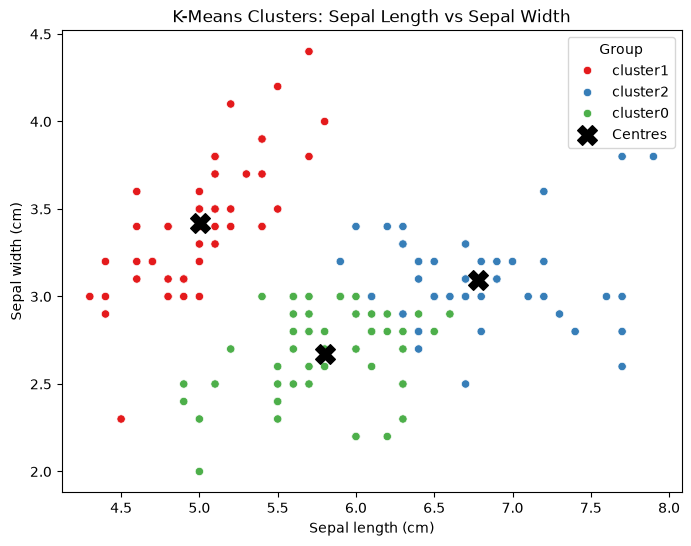

In [21]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x="sepal_length", y="sepal_width", hue="cluster_name",
                palette="Set1", data=df)
plt.scatter(centers["sepal_length"], centers["sepal_width"],
            color="black", marker="X", s=200, label="Centres")
plt.title("K-Means Clusters: Sepal Length vs Sepal Width")
plt.xlabel("Sepal length (cm)")
plt.ylabel("Sepal width (cm)")
plt.legend(title="Group")
os.makedirs("plots", exist_ok=True)

plt.savefig("plots/clusters_sepal.png")
plt.show()

## Compare the clusters with the real species
The computer never saw the species column. Now I check how well its groups match the real species.

In [23]:
pd.crosstab(df["species"],df["cluster_name"])

cluster_name,cluster0,cluster1,cluster2
species,,,
setosa,0,50,0
versicolor,39,0,11
virginica,14,0,36


In [24]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, df["cluster"])
print("Silhouette score:", round(score, 2))

Silhouette score: 0.46


## how good are the clusters
The clusters match the real species well. Setosa is in one cluster on its own. Versicolor and virginica are mostly separated, but 0.46 flowers are mixed between them, because these two species have similar sizes.

## Summary
No label column has been included (species), therefore the algorithm must be able to automatically determine clusters. The data has been standardised to allow each feature to have equal weighting.
From using the elbow method there appears to be a bend in the data at 3 clusters. Therefore, we will use 3 clusters in our model.
Cluster 1 contains the shortest flowers with petal lengths around 1.5cm and widths around 0.25cm. Cluster 0 contains flowers with average size petals with lengths around 4.4cm and widths around 1.4cm. Cluster 2 contain the longest petals, with lengths around 5.5cm and widths around 2cm.
In the petal plot, cluster 1 appears well separated from clusters 0 and 2. However, clusters 0 and 2 appear close together with some overlap in the middle.
In the sepal plot, cluster 1 still appears to be fairly well separated, with small and wide sepals. However, there appears to be a large overlap between cluster 0 and cluster 2, meaning it is not a good idea to separate them based on their sepal sizes.
Therefore, it can be seen that separating based on petal size gives better separation between clusters.
The cluster containing small petals corresponds to setosa. However within the other clusters, there is some mixing between the two clusters as it is difficult to distinguish between versicolor and virginica.
Black X’s indicate the cluster centres. All plots have been saved as images inside the plots folder.